# Machine Learning 3 - Support Vector Machines

A SVM classifier builds a set of hyper-planes to try and separate the data by maximizing the distance between the borders and the data points.

![SVM](http://scikit-learn.org/stable/_images/sphx_glr_plot_separating_hyperplane_0011.png "Decision border in an SVM")

This separation is generally not possible to achieve in the original data space. Therefore, the first step of the SVM is to project the data into a high or infinite dimensions space in which this linear separation can be done. The projection can be done with linear, polynomial, or more comonly "RBF" kernels.

In [1]:
from lab_tools import CIFAR10, evaluate_classifier, get_hog_image

dataset = CIFAR10('CIFAR10/')

Pre-loading training data
Pre-loading test data


**Build a simple SVM** using [the SVC (Support Vector Classfiication) from sklearn](http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC). 
**Train** it on the CIFAR dataset.

In [2]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score

kf = StratifiedKFold(n_splits=5)

# remember: during the cross validation we only split the dataset to each group
# while for stratifiedKFold what you want is mantains the exact same class distribution


cms = []
accs = []

for train,test in kf.split(dataset.train['hog'], dataset.train['labels']):
    train_x = dataset.train['hog'][train]
    train_y = dataset.train['labels'][train]

    svm = SVC()
    svm.fit(train_x, train_y)

    test_x = dataset.train['hog'][test]
    test_y = dataset.train['labels'][test]
    pred = svm.predict(test_x)
    cms.append(confusion_matrix(test_y, pred))
    accs.append(accuracy_score(test_y, pred))



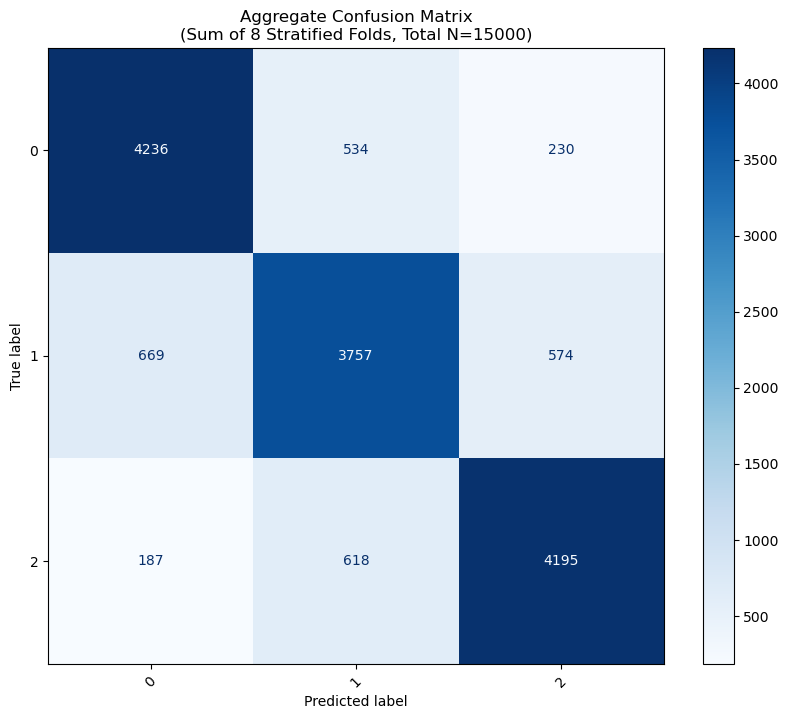

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Sum all the individual confusion matrices from your 'cms' list
# This gives you the total counts of hits and misses across all 8 folds
total_cm = np.sum(cms, axis=0)

# 2. Visualize the aggregate results
fig, ax = plt.subplots(figsize=(10, 8))

# We use the classes from the last 'svm' instance in your loop
disp = ConfusionMatrixDisplay(confusion_matrix=total_cm, 
                              display_labels=svm.classes_)

# Using 'Blues' color map and integer format ('d') for counts
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')

plt.title(f'Aggregate Confusion Matrix\n(Sum of 8 Stratified Folds, Total N={np.sum(total_cm)})')
plt.xticks(rotation=45)
plt.show()

**Explore the classifier**. How many support vectors are there? What are support vectors?

In [4]:
all_support_vectors = svm.support_vectors_ #Each line = 1 "Support Vector" ; 1024 columns forming a 32x32 image 
vectors_per_class = svm.n_support_ #Number of "Support Vector" for each class


print(all_support_vectors)
print(vectors_per_class)


[[4.91446270e-04 8.79407786e-05 1.61013613e-04 ... 4.01766039e-03
  1.25950284e-02 3.89639388e-03]
 [2.33349040e-04 2.06826497e-04 1.88927007e-04 ... 1.58409194e-03
  2.16651574e-03 8.36446624e-03]
 [1.06707910e-02 0.00000000e+00 1.20522593e-03 ... 3.23766195e-03
  2.58587235e-03 2.17043511e-03]
 ...
 [7.36129683e-03 1.64056035e-03 1.73930281e-03 ... 6.72676250e-04
  6.44420519e-04 1.23068958e-03]
 [4.12298412e-03 1.02488609e-03 3.90806416e-04 ... 3.86623230e-04
  5.41179417e-04 2.54309483e-03]
 [1.44819642e-03 1.31054872e-03 6.01302428e-04 ... 4.62258822e-04
  3.46855817e-03 5.50718084e-03]]
[2251 2877 2019]


**Try to find the best "C" (error penalty) and "gamma" parameters** using cross-validation. What influence does "C" have on the number of support vectors?

In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

C_range = np.logspace(-1, 2, 5)
#gamma_range = np.logspace(-1, 2, 5)

acc_C = []
for i in C_range:
    clf = SVC(kernel="rbf", gamma='scale', C = i)
    scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels'], n_jobs=-1).mean()
    acc_C.append(scores)

best_C = C_range[np.argmax(acc_C)]
print(f"Best C: {best_C:.4f}")  



Best gamma: 3.1623


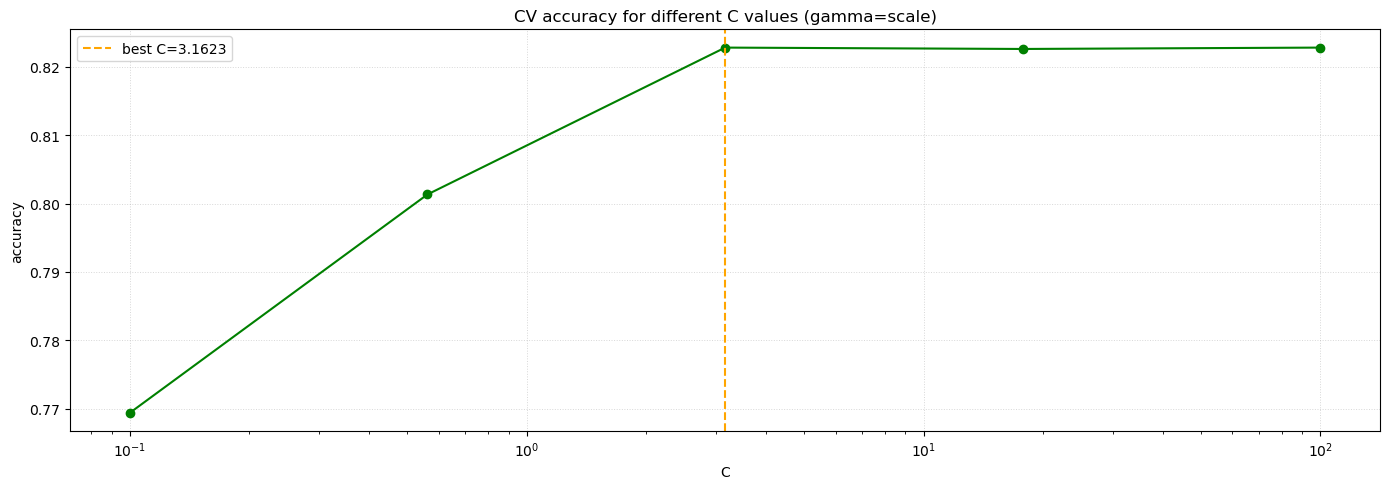

In [12]:
fig, ax2 = plt.subplots(1, figsize=(14, 5))


ax2.plot(C_range, acc_C, marker='o', color='green')
ax2.axvline(best_C, color='orange', linestyle='--', label=f'best C={best_C:.4f}')
ax2.set_xlabel("C")
ax2.set_xscale("log")
ax2.set_ylabel("accuracy")
# Corretto: best_gamma al posto di best_C
ax2.set_title(f"CV accuracy for different C values (gamma=scale)")
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.5, linewidth=0.7)

plt.tight_layout()
# Ho rinominato il file per non sovrascrivere l'eventuale figura completa
fig.savefig("figures/cross_val_svm_C_only.pdf", bbox_inches="tight")
plt.show()

# Comparing algorithms

Using the best hyper-parameters that you found for each of the algorithms (kNN, Decision Trees, Random Forests, MLP, SVM):

* Re-train the models on the full training set.
* Compare their results on the test set.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn import tree
from sklearn import ensemble
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd




mlp  = MLPClassifier(
        hidden_layer_sizes=(100, 100,),
        random_state=2026,
        verbose=False,
        max_iter=1000,
        early_stopping=True,
        tol=0.002,
        n_iter_no_change=50,
    )
dt   = tree.DecisionTreeClassifier(max_depth=8)
rf   = ensemble.RandomForestClassifier(n_estimators=100, max_depth=8, max_features=3 )
knn  = KNeighborsClassifier(n_neighbors=5)
svm  = SVC(kernel="rbf", C=best_C, gamma='scale')

dt.fit(dataset.train['hog'], dataset.train['labels'])
rf.fit(dataset.train['hog'], dataset.train['labels'])
knn.fit(dataset.train['hog'], dataset.train['labels'])
mlp.fit(dataset.train['hog'], dataset.train['labels'])
svm.fit(dataset.train['hog'], dataset.train['labels'])


models = {
    'KNN': knn, 
    'Decision Tree': dt, 
    'Random Forest': rf, 
    'MLP': mlp, 
    'SVM': svm
}

results = []

for name, model in models.items():
    y_pred = model.predict(dataset.test['hog'])
    y_true = dataset.test['labels']
    
    print(f"Classification Report for {name}:")
    print(classification_report(y_true, y_pred, target_names=[f'Class {i}' for i in range(3)]))
